# 06 · ผลการค้นครบทุกชุดดัชนี — Q3 · Q4 · Q5 · Q6

**โครงงาน Sea Level × Wavelet Coherence · วิชา 01204496 · สัปดาห์ที่ 6 (W6) · 🚦 ประตู G3**

| คำถาม | ตอบด้วย |
| --- | --- |
| **Q3** ต้องใช้ดัชนีกี่ตัว | PASC ของชุดที่ดีที่สุดต่อ q + เกณฑ์ "เพิ่มอย่างน้อย 5 จุด" ของ Hu et al. (2017) |
| **Q4** ชุดไหนดีที่สุด | ค่าสูงสุดจาก 218 ชุด + กฎความประหยัด (ชุดเล็กสุดที่อยู่ใน 1 จุดของค่าสูงสุด) |
| **Q5** ดัชนีภูมิภาค (DMI, WNPMI) ช่วยไหม | ชุดที่ดีที่สุดจาก 8 ตัว เทียบจาก 6 ตัวของเปเปอร์ต้นทาง |
| **Q6** PASC ที่พุ่งตามจำนวนดัชนีเป็นของจริงเท่าไร | ส่งข้อมูลที่ **ไม่มีความสัมพันธ์จริง** ผ่านการค้นหาเดียวกันทั้งดุ้น |

ตัวงานคือสคริปต์สามตัว โน้ตบุ๊กนี้อ่านผล ตรวจซ้ำ แล้วตีความ

```
scripts/run_mwc_null.py  -> mwc_null.npz      threshold ต่อ (q, สถานี) จาก null 1000 ชุด                (W5)
scripts/run_mwc.py       -> mwc_search.npz    MWC ของ 218 ชุด × 3 สถานี + PASC/AWC + p ต่อชุด           (Q3–Q5)
scripts/null_control.py  -> null_control.npz  การค้นหาเดียวกันบนข้อมูลที่ไม่มีความสัมพันธ์ 500 รอบ × 2 แบบ  (Q6)
```

## สองเรื่องที่ต้องเข้าใจก่อนอ่านตัวเลข

**(1) threshold ต้องปรับตามจำนวนดัชนี q** (พบใน W5) — noise ล้วน 5 ตัวได้ ρ² ถึง 0.96 ⇒ ทุกตารางในนี้มีสองคอลัมน์
*ปรับ q* (ผลหลักของเรา) และ *ไม่ปรับ* (ใช้ threshold ของ q=1 ตลอด — ไว้เทียบกับเส้นของเปเปอร์ต้นทางเท่านั้น)

**(2) การเลือก "ชุดที่ดีที่สุด" ทำให้ค่าสูงขึ้นเอง** — ค่าสูงสุดของ 56 ชุดย่อมสูงกว่าค่าของชุดเดียวแม้ทุกชุดเป็น noise
⇒ ชุดที่ดีที่สุดต้องเทียบกับ **null ของค่าสูงสุดจากการค้นหาเดียวกัน** ไม่ใช่ null ของชุดเดียว · null มีสองแบบ

| แบบ | สร้างอย่างไร | เก็บอะไรของจริงไว้ |
| --- | --- | --- |
| `fake_x` ดัชนีปลอม (ตาม proposal) | Y จริง + ดัชนี AR(1) อิสระ 8 ตัว ความแดงเท่าของจริง | Y ทั้งเส้น |
| `fake_y` Y ปลอม | Y เป็น AR(1) + ดัชนีจริง 8 ตัว | โครงสร้างของดัชนีทั้งหมด รวมสหสัมพันธ์ระหว่างกัน |

In [1]:
import json, sys, time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); sys.path.insert(0, str(ROOT / "scripts"))

from wtc.coherence import mwc_cached
from wtc.metrics import BANDS, pasc, significance
from wtc.search import all_subsets, best_per_q, evaluate_subsets, gains, prepare_station, within_of_max
from wtc.plotting import plot_coherence, use_thai_font

FIGURES = ROOT / "figures"; FIGURES.mkdir(exist_ok=True)
use_thai_font()

P = ROOT / "data" / "processed"
d = np.load(P / "series.npz", allow_pickle=True)
nul = np.load(P / "mwc_null.npz", allow_pickle=True)
srch = np.load(P / "mwc_search.npz", allow_pickle=True)
nc = np.load(P / "null_control.npz", allow_pickle=True)

stations = [str(s) for s in srch["stations"]]; bands = [str(b) for b in srch["bands"]]
xn = [str(s) for s in srch["indices"]]
subsets = [tuple(s) for s in json.loads(str(srch["subsets"]))]
q = srch["q"]; in6 = srch["in_paper6"]; QS = sorted(set(int(v) for v in q))
smeta = json.loads(str(srch["meta"])); ncmeta = json.loads(str(nc["meta"]))
designs = [str(s) for s in nc["designs"]]
MAIN = stations[0]; PRIMARY = smeta["primary_bands"]
NAME = {"nino34": "Niño3.4", "soi": "SOI", "pdo": "PDO", "amo": "AMO", "nao": "NAO",
        "tpi": "TPI", "dmi": "DMI", "wnpmi": "WNPMI"}
LABEL = {"ko_taphao_noi": "KO TAPHAO NOI (อันดามัน)", "ko_lak": "KO LAK (อ่าวไทย)",
         "fort_phrachula_chomklao": "FORT PHRACHULA (อ่าวไทยตอนบน)"}
DESIGN = {"fake_x": "ดัชนีปลอม", "fake_y": "Y ปลอม"}
lab = lambda s: "+".join(NAME[k] for k in s)
pval = lambda obs, null: float((np.sum(null >= obs - 1e-9) + 1) / (len(null) + 1))
PAPER_PASC = {1: 14.03, 2: 49.63, 3: 81.11, 4: 96.00}     # ค่าเฉลี่ย 82 สถานีของเปเปอร์ (source-paper-detail §4.2)

OBS, OBSF, PV = srch["pasc"], srch["pasc_fixed"], srch["p"]     # (สถานี, ชุด, แถบ)
NP_, NPF = nc["pasc"], nc["pasc_fixed"]                          # (สถานี, แบบ, รอบ, ชุด, แถบ)
print(f"{len(stations)} สถานี × {len(subsets)} ชุด · null ต่อชุด {smeta['null_nmc']} surrogate · "
      f"null ของการค้นหา {ncmeta['nrep']} รอบ × {len(designs)} แบบ")
assert MAIN == "ko_taphao_noi" and len(subsets) == 218 and ncmeta["nrep"] >= 500
assert [tuple(s) for s in json.loads(str(nc["subsets"]))] == subsets
assert int(srch["n_nan"].sum()) == 0          # ไม่มีจุดในกรวยที่ cond เกินเกณฑ์เลยทั้ง 3 สถานี × 218 ชุด
print(f"จุด NaN ในกรวยรวมทุกสถานีทุกชุด: 0 · cond สูงสุดในกรวย {np.nanmax(srch['cond_max']):.0f} (เกณฑ์ 1e8)")

3 สถานี × 218 ชุด · null ต่อชุด 1000 surrogate · null ของการค้นหา 1000 รอบ × 2 แบบ
จุด NaN ในกรวยรวมทุกสถานีทุกชุด: 0 · cond สูงสุดในกรวย 63091 (เกณฑ์ 1e8)


## 1. Q6 — PASC ที่พุ่งตามจำนวนดัชนี เป็นของจริงเท่าไร

เริ่มที่ Q6 ก่อน เพราะมันกำหนดว่าตัวเลขที่เหลือทั้งหมดต้องอ่านอย่างไร
เส้นแต่ละเส้นคือ **PASC เฉลี่ยของทุกชุดขนาด q** (ทั้งระนาบ) ที่ KO TAPHAO NOI

 q │ ไม่ปรับ: จริง    ปลอม  จริง−ปลอม │ ปรับ q: จริง    ปลอม │ เปเปอร์
 1 │           9.3     4.8       +4.5 │          9.3     4.8 │   14.0
 2 │          35.1    25.7       +9.5 │         10.0     4.8 │   49.6
 3 │          67.5    59.8       +7.6 │          9.7     4.7 │   81.1
 4 │          90.2    86.4       +3.8 │          9.3     4.6 │   96.0
 5 │          98.5    97.2       +1.3 │          8.8     4.6 │      —


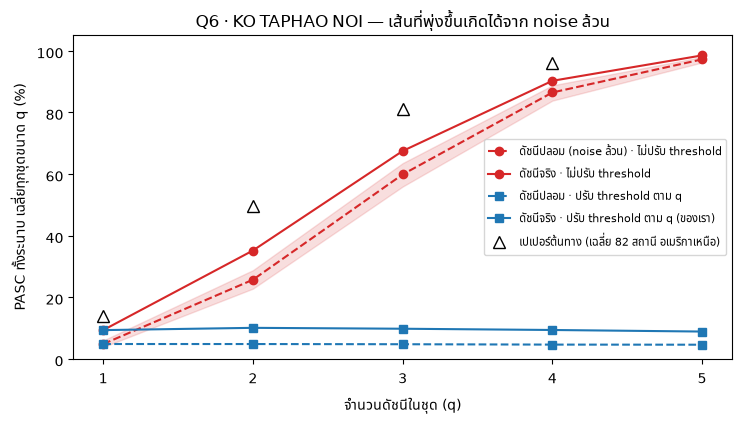

In [2]:
kb = bands.index("ทั้งระนาบ"); dx = designs.index("fake_x")
def mean_by_q(a):                                  # a: (..., ชุด) -> ค่าเฉลี่ยต่อ q
    return np.array([np.nanmean(a[..., q == k]) for k in QS])

real_fix, real_adj = mean_by_q(OBSF[0][:, kb]), mean_by_q(OBS[0][:, kb])
fake_fix, fake_adj = mean_by_q(NPF[0, dx][:, :, kb]), mean_by_q(NP_[0, dx][:, :, kb])
# ช่วง 5–95% ของ "ค่าเฉลี่ยทุกชุดขนาด q" ข้ามรอบของ null
band_fix = np.array([np.percentile(np.nanmean(NPF[0, dx][:, q == k, kb], axis=1), [5, 95]) for k in QS])

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.fill_between(QS, band_fix[:, 0], band_fix[:, 1], color="C3", alpha=0.15)
ax.plot(QS, fake_fix, "o--", color="C3", label="ดัชนีปลอม (noise ล้วน) · ไม่ปรับ threshold")
ax.plot(QS, real_fix, "o-", color="C3", label="ดัชนีจริง · ไม่ปรับ threshold")
ax.plot(QS, fake_adj, "s--", color="C0", label="ดัชนีปลอม · ปรับ threshold ตาม q")
ax.plot(QS, real_adj, "s-", color="C0", label="ดัชนีจริง · ปรับ threshold ตาม q (ของเรา)")
ax.plot(list(PAPER_PASC), list(PAPER_PASC.values()), "k^", ms=8, mfc="none",
        label="เปเปอร์ต้นทาง (เฉลี่ย 82 สถานี อเมริกาเหนือ)")
ax.set_xticks(QS); ax.set_xlabel("จำนวนดัชนีในชุด (q)"); ax.set_ylabel("PASC ทั้งระนาบ เฉลี่ยทุกชุดขนาด q (%)")
ax.set_ylim(0, 105); ax.legend(fontsize=8, loc="center right")
ax.set_title("Q6 · KO TAPHAO NOI — เส้นที่พุ่งขึ้นเกิดได้จาก noise ล้วน")
fig.savefig(FIGURES / "w6-q6-false-floor.png", dpi=130, bbox_inches="tight")

print(f"{'q':>2s} │ {'ไม่ปรับ: จริง':>13s} {'ปลอม':>7s} {'จริง−ปลอม':>10s} │ {'ปรับ q: จริง':>12s} {'ปลอม':>7s} │ เปเปอร์")
for i, k in enumerate(QS):
    pp = f"{PAPER_PASC[k]:6.1f}" if k in PAPER_PASC else "     —"
    print(f"{k:2d} │ {real_fix[i]:13.1f} {fake_fix[i]:7.1f} {real_fix[i] - fake_fix[i]:+10.1f} │ "
          f"{real_adj[i]:12.1f} {fake_adj[i]:7.1f} │ {pp}")
assert fake_fix[-1] > 90 and all(3.5 < v < 6.5 for v in fake_adj)

**อ่านผล**
- เส้นแดงประ: **ดัชนีปลอมที่ไม่เกี่ยวกับระดับน้ำเลย ได้ PASC ขึ้นจาก ~5% ไปเกิน 95%** เมื่อไม่ปรับ threshold —
  รูปเดียวกับเส้นของเปเปอร์ต้นทาง (สามเหลี่ยม) ⇒ "ยิ่งรวมดัชนียิ่งอธิบายได้" เป็นสมบัติของตัววัด ไม่ใช่ของข้อมูล
- เส้นแดงทึบ (ดัชนีจริง ไม่ปรับ) สูงกว่าเส้นประเพียงเล็กน้อย — ส่วนต่างนั้นคือสัญญาณจริงทั้งหมดที่มี
- เส้นน้ำเงินประ: พอปรับ threshold ตาม q ดัชนีปลอมได้ ~5% ทุก q ตามนิยามของเกณฑ์ 95% ⇒ ตัวเลขที่ปรับแล้วเทียบข้าม q ได้
- เส้นน้ำเงินทึบ: ดัชนีจริงหลังปรับ — **ไม่ขึ้นตาม q** (รายละเอียดในหัวข้อ 2)

## 2. Q3 — ต้องใช้ดัชนีกี่ตัว

ชุดที่ดีที่สุดต่อ q ของข้อมูลจริง เทียบกับ **ค่าสูงสุดต่อ q ของ null** (ผ่านการค้นหาเดียวกัน)

In [3]:
def q3_table(si, band):
    kb = bands.index(band)
    best = best_per_q(q, OBS[si][:, kb]); g = gains(best)
    rows = []
    for k in QS:
        j, v = best[k]
        r = dict(q=k, subset=subsets[j], pasc=v, gain=g.get(k), p_single=PV[si][j, kb], fixed=OBSF[si][j, kb])
        for di, de in enumerate(designs):
            nmax = np.nanmax(NP_[si, di][:, q == k, kb], axis=1)
            r[de] = dict(p95=np.percentile(nmax, 95), med=np.median(nmax), p=pval(v, nmax))
        rows.append(r)
    return rows

def print_q3(si, band):
    print(f"\n{LABEL[stations[si]]} · แถบ {band}")
    print(f"  {'q':>2s} │ {'ชุดที่ดีที่สุด':32s} {'PASC':>6s} {'เพิ่ม':>6s} │ {'p ชุดเดียว':>10s} │ "
          + " │ ".join(f"{'null สูงสุด 95% · p (' + DESIGN[de] + ')':>30s}" for de in designs) + f" │ {'ไม่ปรับ':>7s}")
    for r in q3_table(si, band):
        g = f"{r['gain']:+6.1f}" if r["gain"] is not None else "     —"
        print(f"  {r['q']:2d} │ {lab(r['subset']):32s} {r['pasc']:6.1f} {g} │ {r['p_single']:10.3f} │ "
              + " │ ".join(f"{r[de]['p95']:18.1f} · {r[de]['p']:.3f}   " for de in designs) + f" │ {r['fixed']:7.1f}")

for band in PRIMARY:
    print_q3(0, band)


KO TAPHAO NOI (อันดามัน) · แถบ ทั้งระนาบ
   q │ ชุดที่ดีที่สุด                     PASC  เพิ่ม │ p ชุดเดียว │ null สูงสุด 95% · p (ดัชนีปลอม) │   null สูงสุด 95% · p (Y ปลอม) │ ไม่ปรับ
   1 │ SOI                                14.3      — │      0.002 │               11.4 · 0.010    │               11.5 · 0.010    │    14.3
   2 │ DMI+WNPMI                          14.4   +0.2 │      0.002 │               12.2 · 0.011    │               12.6 · 0.014    │    42.7
   3 │ SOI+AMO+DMI                        15.1   +0.6 │      0.001 │               12.2 · 0.008    │               13.0 · 0.010    │    75.5
   4 │ SOI+AMO+DMI+WNPMI                  14.0   -1.1 │      0.001 │               11.5 · 0.009    │               12.4 · 0.009    │    93.1
   5 │ Niño3.4+SOI+AMO+DMI+WNPMI          12.5   -1.5 │      0.004 │               10.6 · 0.014    │               11.7 · 0.023    │    98.5

KO TAPHAO NOI (อันดามัน) · แถบ 2–7 ปี
   q │ ชุดที่ดีที่สุด                     PASC  เพิ่ม │ p ชุดเดียว │ n

✅ ทั้งสองแถบ: ไม่มีขั้นไหนที่การเพิ่มดัชนีได้ถึง +5 จุด ⇒ ตามเกณฑ์ของ Hu et al. (2017) ดัชนีเดียวพอ


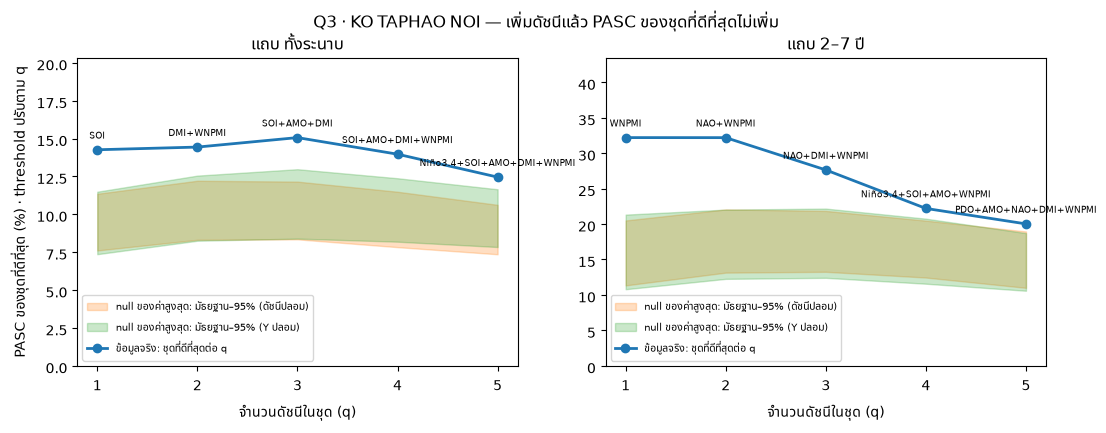

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4), sharey=False)
for ax, band in zip(axes, PRIMARY):
    rows = q3_table(0, band)
    for de, c in zip(designs, ("C1", "C2")):
        ax.fill_between(QS, [r[de]["med"] for r in rows], [r[de]["p95"] for r in rows], color=c, alpha=0.25,
                        label=f"null ของค่าสูงสุด: มัธยฐาน–95% ({DESIGN[de]})")
    ax.plot(QS, [r["pasc"] for r in rows], "o-", color="C0", lw=2, label="ข้อมูลจริง: ชุดที่ดีที่สุดต่อ q")
    for r in rows:
        ax.annotate(lab(r["subset"]), (r["q"], r["pasc"]), textcoords="offset points", xytext=(0, 8),
                    ha="center", fontsize=6.5)
    ax.set_xticks(QS); ax.set_xlabel("จำนวนดัชนีในชุด (q)"); ax.set_title(f"แถบ {band}")
    ax.set_ylim(0, max(r["pasc"] for r in rows) * 1.35); ax.legend(fontsize=7.5, loc="lower left")
axes[0].set_ylabel("PASC ของชุดที่ดีที่สุด (%) · threshold ปรับตาม q")
fig.suptitle("Q3 · KO TAPHAO NOI — เพิ่มดัชนีแล้ว PASC ของชุดที่ดีที่สุดไม่เพิ่ม", y=1.0)
fig.savefig(FIGURES / "w6-q3-best-per-q.png", dpi=130, bbox_inches="tight")

for band in PRIMARY:
    g = gains(best_per_q(q, OBS[0][:, bands.index(band)]))
    assert max(g.values()) < smeta["gain_rule"], (band, g)
print(f"✅ ทั้งสองแถบ: ไม่มีขั้นไหนที่การเพิ่มดัชนีได้ถึง +{smeta['gain_rule']:g} จุด ⇒ ตามเกณฑ์ของ Hu et al. (2017) ดัชนีเดียวพอ")

## 3. Q4 — ชุดไหนดีที่สุด และเชื่อได้แค่ไหน

`p ทั้งตระกูล` = สัดส่วนของรอบ null ที่ **ค่าสูงสุดจากทั้ง 218 ชุด** สูงเท่าหรือมากกว่าชุดนี้ (max-statistic)
⇒ คุมโอกาสผิดพลาดของการทดสอบทั้ง 218 ชุดพร้อมกัน และไม่ต้องสมมติว่าชุดต่าง ๆ เป็นอิสระต่อกัน
(Benjamini–Hochberg ใช้ที่นี่ไม่ได้ผล: p ต่อชุดละเอียดสุด 1/1001 แต่มี 654 การทดสอบที่ซ้อนทับกันหนัก ⇒ ไม่มีชุดใดผ่าน)

In [5]:
fwer = {}
for band in PRIMARY:
    kb = bands.index(band)
    v = OBS[0][:, kb]
    nall = {de: np.nanmax(NP_[0, di][:, :, kb], axis=1) for di, de in enumerate(designs)}
    pf = {de: np.array([pval(x, nall[de]) for x in v]) for de in designs}
    fwer[band] = pf
    order = np.argsort(-v)[:10]
    top, pars = int(np.nanargmax(v)), within_of_max(v, q, 1.0)
    print(f"\nKO TAPHAO NOI · แถบ {band} — 10 อันดับแรกจาก 218 ชุด")
    print(f"  {'ชุด':34s} {'q':>2s} {'PASC':>6s} {'AWC':>5s} {'p ชุดเดียว':>10s} │ " +
          " ".join(f"{'p ทั้งตระกูล (' + DESIGN[de] + ')':>24s}" for de in designs))
    for j in order:
        print(f"  {lab(subsets[j]):34s} {q[j]:2d} {v[j]:6.1f} {srch['awc'][0][j, kb]:5.2f} {PV[0][j, kb]:10.3f} │ "
              + " ".join(f"{pf[de][j]:24.3f}" for de in designs))
    print(f"  null ของค่าสูงสุดทั้ง 218 ชุด — 95%: " + " · ".join(f"{DESIGN[de]} {np.percentile(nall[de], 95):.1f}%" for de in designs))
    print(f"  ชุดที่ผ่าน p ทั้งตระกูล < 0.05: " + " · ".join(f"{DESIGN[de]} {(pf[de] < 0.05).sum()} ชุด" for de in designs)
          + f"   (p ชุดเดียว < 0.05: {(PV[0][:, kb] < 0.05).sum()} ชุด)")
    print(f"  ⇒ สูงสุด: {lab(subsets[top])} ({v[top]:.1f}%) · **ประหยัดสุดใน 1 จุด: {lab(subsets[pars])} ({v[pars]:.1f}%)**")


KO TAPHAO NOI · แถบ ทั้งระนาบ — 10 อันดับแรกจาก 218 ชุด
  ชุด                                 q   PASC   AWC p ชุดเดียว │ p ทั้งตระกูล (ดัชนีปลอม)    p ทั้งตระกูล (Y ปลอม)
  SOI+AMO+DMI                         3   15.1  0.91      0.001 │                    0.022                    0.020
  DMI+WNPMI                           2   14.4  0.84      0.002 │                    0.028                    0.029
  AMO+DMI+WNPMI                       3   14.3  0.92      0.001 │                    0.029                    0.033
  SOI                                 1   14.3  0.71      0.002 │                    0.029                    0.034
  SOI+AMO+DMI+WNPMI                   4   14.0  0.95      0.001 │                    0.031                    0.047
  AMO+DMI                             2   13.7  0.84      0.003 │                    0.037                    0.053
  DMI                                 1   13.6  0.70      0.003 │                    0.040                    0.059
  SOI+DMI      

In [6]:
exact = json.loads(str(srch["exact"]))
print("ตรวจ: null รวมต่อ q เทียบ null เจาะจงชุด ของชุดที่ดีที่สุดต่อ q (สถานีหลัก)")
print(f"  {'ชุด':34s} │ " + " │ ".join(f"{b + ': รวม → เจาะจง (p)':^36s}" for b in PRIMARY))
worst = 0.0
for name, rec in exact.items():
    cells = []
    for b in PRIMARY:
        r = rec[b]; worst = max(worst, abs(r["pasc_exact"] - r["pasc_pooled"]))
        cells.append(f"{r['pasc_pooled']:5.1f} ({r['p_pooled']:.3f}) → {r['pasc_exact']:5.1f} ({r['p_exact']:.3f})")
    print(f"  {lab(name.split('+')):34s} │ " + " │ ".join(f"{c:^36s}" for c in cells))
print(f"ต่างกันมากสุด {worst:.1f} จุดร้อยละ")
assert len(exact) >= 4

ตรวจ: null รวมต่อ q เทียบ null เจาะจงชุด ของชุดที่ดีที่สุดต่อ q (สถานีหลัก)
  ชุด                                │     ทั้งระนาบ: รวม → เจาะจง (p)      │       2–7 ปี: รวม → เจาะจง (p)      
  DMI+WNPMI                          │     14.4 (0.002) →  14.3 (0.001)     │     26.9 (0.002) →  26.1 (0.001)    
  NAO+WNPMI                          │     12.8 (0.005) →  12.9 (0.006)     │     32.2 (0.001) →  32.3 (0.002)    
  NAO+DMI+WNPMI                      │     13.1 (0.004) →  13.3 (0.003)     │     27.6 (0.002) →  28.1 (0.001)    
  SOI+AMO+DMI                        │     15.1 (0.001) →  14.9 (0.002)     │     21.3 (0.007) →  21.7 (0.003)    
  Niño3.4+SOI+AMO+WNPMI              │     12.4 (0.002) →  12.6 (0.007)     │     22.2 (0.003) →  22.7 (0.002)    
  SOI+AMO+DMI+WNPMI                  │     14.0 (0.001) →  13.9 (0.002)     │     21.4 (0.004) →  21.2 (0.003)    
  Niño3.4+SOI+AMO+DMI+WNPMI          │     12.5 (0.004) →  12.2 (0.003)     │     18.9 (0.003) →  17.8 (0.004)    
  PD

## 4. Q5 ⭐ — ดัชนีภูมิภาค (DMI + WNPMI) เพิ่มอำนาจอธิบายเหนือชุด 6 ตัวของเปเปอร์ต้นทางไหม

เทียบชุดที่ดีที่สุดที่เลือกได้จากดัชนี **8 ตัว** กับที่เลือกได้จาก **6 ตัวของเปเปอร์** (Niño3.4, PDO, NAO, SOI, AMO, TPI)
การมีตัวเลือกมากกว่าย่อมได้ค่าสูงสุดมากกว่าหรือเท่าเดิมเสมอ ⇒ ส่วนต่างต้องเทียบกับส่วนต่างแบบเดียวกันใน null


แถบ ทั้งระนาบ
   q │ จาก 8 ตัว                        PASC │ จาก 6 ตัว                        PASC │    8−6    p (ดัชนีปลอม)       p (Y ปลอม)
   1 │ SOI                              14.3 │ SOI                              14.3 │   +0.0            1.000            1.000
   2 │ DMI+WNPMI                        14.4 │ SOI+NAO                          13.3 │   +1.1            0.268            0.246
   3 │ SOI+AMO+DMI                      15.1 │ SOI+PDO+AMO                      12.0 │   +3.1            0.086            0.085
   4 │ SOI+AMO+DMI+WNPMI                14.0 │ SOI+PDO+AMO+NAO                  11.7 │   +2.2            0.239            0.289
   5 │ Niño3.4+SOI+AMO+DMI+WNPMI        12.5 │ Niño3.4+SOI+AMO+NAO+TPI           9.3 │   +3.2            0.138            0.239
  รวมทุก q: สูงสุดจาก 8 ตัว − สูงสุดจาก 6 ตัว = +0.8 จุด   |   ดัชนีปลอม: 95% ของ null +3.6 · p = 0.412   |   Y ปลอม: 95% ของ null +3.8 · p = 0.427

แถบ 2–7 ปี
   q │ จาก 8 ตัว                        PASC │ จาก 6 ตัว 

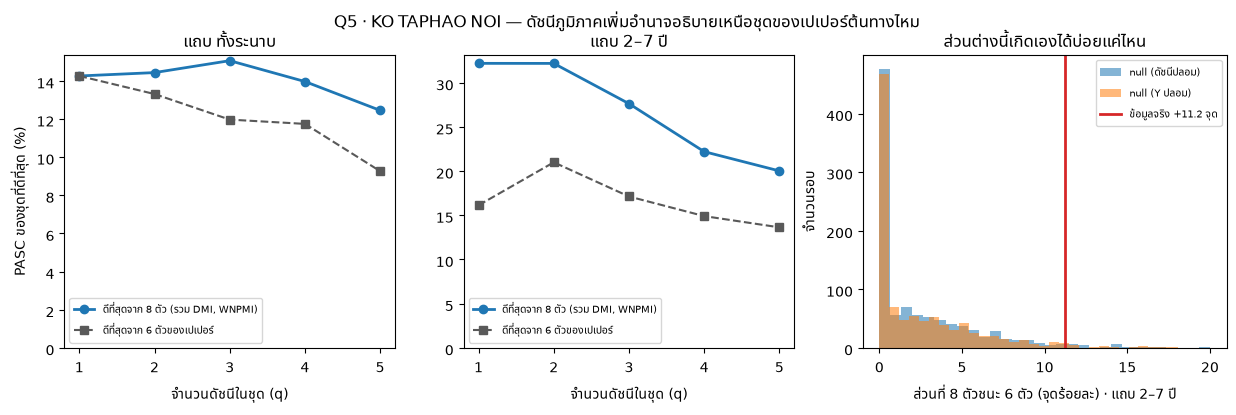

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), gridspec_kw={"width_ratios": [1, 1, 1.1]})
for ax, band in zip(axes, PRIMARY):
    kb = bands.index(band)
    b8 = best_per_q(q, OBS[0][:, kb]); b6 = best_per_q(q, OBS[0][:, kb], in6)
    ax.plot(QS, [b8[k][1] for k in QS], "o-", color="C0", lw=2, label="ดีที่สุดจาก 8 ตัว (รวม DMI, WNPMI)")
    ax.plot(QS, [b6[k][1] for k in QS], "s--", color="0.35", label="ดีที่สุดจาก 6 ตัวของเปเปอร์")
    ax.set_xticks(QS); ax.set_xlabel("จำนวนดัชนีในชุด (q)"); ax.set_title(f"แถบ {band}")
    ax.set_ylim(0, None); ax.legend(fontsize=7.5)
    print(f"\nแถบ {band}")
    print(f"  {'q':>2s} │ {'จาก 8 ตัว':30s} {'PASC':>6s} │ {'จาก 6 ตัว':30s} {'PASC':>6s} │ {'8−6':>6s} " +
          " ".join(f"{'p (' + DESIGN[de] + ')':>16s}" for de in designs))
    for k in QS:
        m = q == k
        ps = []
        for di in range(len(designs)):
            ng = np.nanmax(NP_[0, di][:, m, kb], axis=1) - np.nanmax(NP_[0, di][:, m & in6, kb], axis=1)
            ps.append(pval(b8[k][1] - b6[k][1], ng))
        print(f"  {k:2d} │ {lab(subsets[b8[k][0]]):30s} {b8[k][1]:6.1f} │ {lab(subsets[b6[k][0]]):30s} {b6[k][1]:6.1f} │ "
              f"{b8[k][1] - b6[k][1]:+6.1f} " + " ".join(f"{p_:16.3f}" for p_ in ps))
    o = np.nanmax(OBS[0][:, kb]) - np.nanmax(OBS[0][in6, kb])
    line = []
    for di, de in enumerate(designs):
        ng = np.nanmax(NP_[0, di][:, :, kb], axis=1) - np.nanmax(NP_[0, di][:, in6, kb], axis=1)
        line.append(f"{DESIGN[de]}: 95% ของ null {np.percentile(ng, 95):+.1f} · p = {pval(o, ng):.3f}")
        if band == "2–7 ปี":
            axes[2].hist(ng, bins=30, alpha=0.55, label=f"null ({DESIGN[de]})")
    print(f"  รวมทุก q: สูงสุดจาก 8 ตัว − สูงสุดจาก 6 ตัว = {o:+.1f} จุด   |   " + "   |   ".join(line))
    if band == "2–7 ปี":
        axes[2].axvline(o, color="C3", lw=2, label=f"ข้อมูลจริง {o:+.1f} จุด")
axes[0].set_ylabel("PASC ของชุดที่ดีที่สุด (%)")
axes[2].set_xlabel("ส่วนที่ 8 ตัวชนะ 6 ตัว (จุดร้อยละ) · แถบ 2–7 ปี"); axes[2].set_ylabel("จำนวนรอบ")
axes[2].set_title("ส่วนต่างนี้เกิดเองได้บ่อยแค่ไหน"); axes[2].legend(fontsize=7.5)
fig.suptitle("Q5 · KO TAPHAO NOI — ดัชนีภูมิภาคเพิ่มอำนาจอธิบายเหนือชุดของเปเปอร์ต้นทางไหม", y=1.0)
fig.savefig(FIGURES / "w6-q5-regional.png", dpi=130, bbox_inches="tight")

## 5. ดัชนีตัวไหนอยู่ในชุดที่ดี — ส่วนร่วมของแต่ละดัชนี

PASC เฉลี่ยของชุดที่ **มี** ดัชนีตัวนั้น ลบ PASC เฉลี่ยของชุดที่ **ไม่มี** (ที่ q เดียวกัน แล้วเฉลี่ยข้าม q = 1..5)
ถ้าดัชนีเป็นตัวหลักจริง การมีมันในชุดต้องยกค่าขึ้นสม่ำเสมอ ไม่ใช่เฉพาะในชุดเดียวที่บังเอิญชนะ

แถบ ทั้งระนาบ: SOI +3.2* · DMI +2.2* · WNPMI +1.6 · AMO -0.0 · Niño3.4 -0.8 · NAO -1.6 · TPI -2.0* · PDO -2.5*
แถบ 2–7 ปี: WNPMI +7.7* · SOI +1.6 · DMI +1.5 · AMO +1.0 · NAO -1.0 · Niño3.4 -2.4* · TPI -3.2* · PDO -5.3*


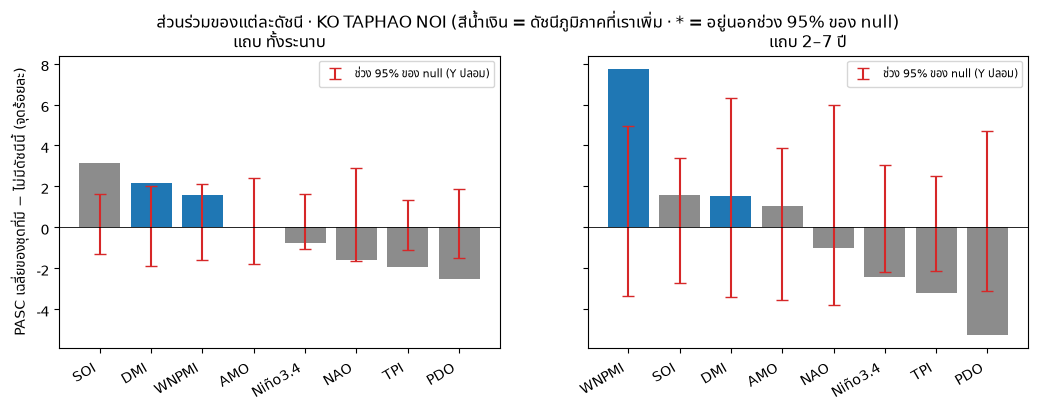

In [8]:
def contribution(values):                           # values: (..., ชุด) -> (..., ดัชนี)
    out = []
    for name in xn:
        has = np.array([name in s for s in subsets])
        out.append(np.mean([np.nanmean(values[..., (q == k) & has], axis=-1)
                            - np.nanmean(values[..., (q == k) & ~has], axis=-1) for k in QS], axis=0))
    return np.stack(out, axis=-1)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8), sharey=True)
dy = designs.index("fake_y")
for ax, band in zip(axes, PRIMARY):
    kb = bands.index(band)
    obs_c = contribution(OBS[0][:, kb])
    null_c = contribution(NP_[0, dy][:, :, kb])                       # (รอบ, ดัชนี)
    lo, hi = np.percentile(null_c, [2.5, 97.5], axis=0)
    order = np.argsort(-obs_c)
    ax.bar(range(len(xn)), obs_c[order], color=["C0" if xn[i] in ("dmi", "wnpmi") else "0.55" for i in order])
    ax.errorbar(range(len(xn)), ((lo + hi) / 2)[order], yerr=((hi - lo) / 2)[order], fmt="none", ecolor="C3",
                capsize=4, label="ช่วง 95% ของ null (Y ปลอม)")
    ax.set_xticks(range(len(xn))); ax.set_xticklabels([NAME[xn[i]] for i in order], rotation=30, ha="right")
    ax.axhline(0, color="k", lw=0.6); ax.set_title(f"แถบ {band}"); ax.legend(fontsize=8)
    print(f"แถบ {band}: " + " · ".join(f"{NAME[xn[i]]} {obs_c[i]:+.1f}{'*' if not lo[i] <= obs_c[i] <= hi[i] else ''}" for i in order))
axes[0].set_ylabel("PASC เฉลี่ยของชุดที่มี − ไม่มีดัชนีนี้ (จุดร้อยละ)")
fig.suptitle("ส่วนร่วมของแต่ละดัชนี · KO TAPHAO NOI (สีน้ำเงิน = ดัชนีภูมิภาคที่เราเพิ่ม · * = อยู่นอกช่วง 95% ของ null)", y=1.0)
fig.savefig(FIGURES / "w6-index-contribution.png", dpi=130, bbox_inches="tight")

## 6. สถานีสำรอง — KO LAK และ FORT PHRACHULA (วัตถุดิบของ Q2 และ Q8)

คำนวณไว้ครบตาม PLAN.md §1.4 จะเขียนลงรายงานหรือไม่ตัดสินที่ปลาย W6

In [9]:
for si in range(len(stations)):
    print(f"\n{LABEL[stations[si]]}")
    for band in PRIMARY:
        kb = bands.index(band)
        v = OBS[si][:, kb]; top = int(np.nanargmax(v))
        ps = [pval(v[top], np.nanmax(NP_[si, di][:, :, kb], axis=1)) for di in range(len(designs))]
        n1 = int((PV[si][:, kb] < 0.05).sum())
        print(f"  แถบ {band:10s} สูงสุดจาก 218 ชุด: {lab(subsets[top]):28s} {v[top]:5.1f}%  p ทั้งตระกูล "
              + " · ".join(f"{DESIGN[de]} {p_:.3f}" for de, p_ in zip(designs, ps)) + f"   (p ชุดเดียว < 0.05: {n1} ชุด)")


KO TAPHAO NOI (อันดามัน)
  แถบ ทั้งระนาบ  สูงสุดจาก 218 ชุด: SOI+AMO+DMI                   15.1%  p ทั้งตระกูล ดัชนีปลอม 0.022 · Y ปลอม 0.020   (p ชุดเดียว < 0.05: 136 ชุด)
  แถบ 2–7 ปี     สูงสุดจาก 218 ชุด: WNPMI                         32.2%  p ทั้งตระกูล ดัชนีปลอม 0.005 · Y ปลอม 0.006   (p ชุดเดียว < 0.05: 107 ชุด)

KO LAK (อ่าวไทย)
  แถบ ทั้งระนาบ  สูงสุดจาก 218 ชุด: Niño3.4+SOI+DMI                8.9%  p ทั้งตระกูล ดัชนีปลอม 0.294 · Y ปลอม 0.591   (p ชุดเดียว < 0.05: 1 ชุด)
  แถบ 2–7 ปี     สูงสุดจาก 218 ชุด: Niño3.4+AMO                   14.6%  p ทั้งตระกูล ดัชนีปลอม 0.448 · Y ปลอม 0.503   (p ชุดเดียว < 0.05: 1 ชุด)

FORT PHRACHULA (อ่าวไทยตอนบน)
  แถบ ทั้งระนาบ  สูงสุดจาก 218 ชุด: DMI+WNPMI                      7.9%  p ทั้งตระกูล ดัชนีปลอม 0.714 · Y ปลอม 0.802   (p ชุดเดียว < 0.05: 0 ชุด)
  แถบ 2–7 ปี     สูงสุดจาก 218 ชุด: SOI+NAO+DMI                   14.3%  p ทั้งตระกูล ดัชนีปลอม 0.514 · Y ปลอม 0.547   (p ชุดเดียว < 0.05: 6 ชุด)


## 7. หน้าตาของ MWC — ชุดเดี่ยวที่ดีที่สุด เทียบกับชุดห้าตัวที่ดีที่สุด (แถบ 2–7 ปี)

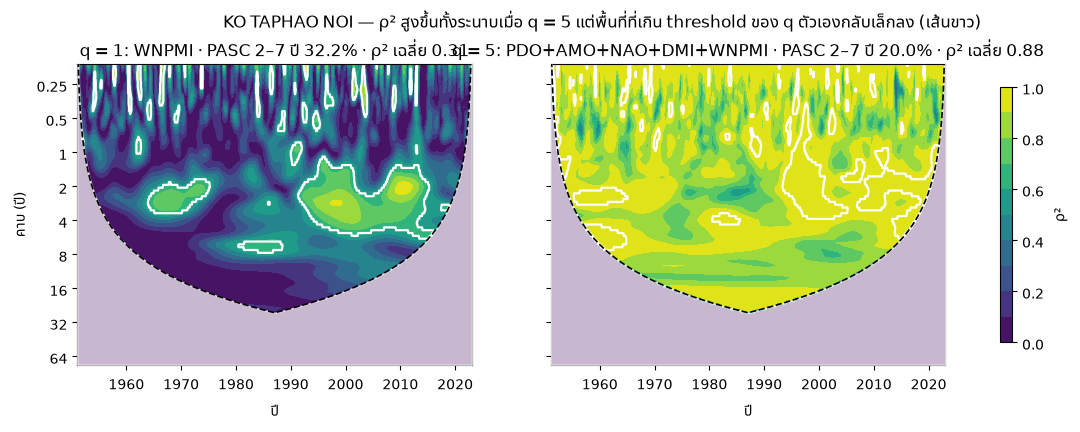

In [10]:
cache, periods, coi, scales, inside, ok = prepare_station(d, MAIN)
thr = {k: nul["threshold"][0, i] for i, k in enumerate(nul["qs"].tolist())}
kb = bands.index("2–7 ปี"); b8 = best_per_q(q, OBS[0][:, kb])
fig, axes = plt.subplots(1, 2, figsize=(14, 3.9), sharey=True)
for ax, k in zip(axes, (1, 5)):
    s = subsets[b8[k][0]]
    R2, _ = mwc_cached(cache, "y", s, where=inside)
    valid = inside & np.isfinite(R2) & ok["y"]
    for name in s:
        valid = valid & ok[name]
    sig = significance(R2, thr[k]) & valid
    cf = plot_coherence(ax, d["t"], periods, np.nan_to_num(R2), coi, sig_mask=sig,
                        title=f"q = {k}: {lab(s)} · PASC 2–7 ปี {b8[k][1]:.1f}% · ρ² เฉลี่ย {np.nanmean(R2[valid]):.2f}")
    ax.axhspan(2, 7, color="w", alpha=0.0)
axes[1].set_ylabel("")
fig.colorbar(cf, ax=axes, shrink=0.85, label="ρ²")
fig.suptitle("KO TAPHAO NOI — ρ² สูงขึ้นทั้งระนาบเมื่อ q = 5 แต่พื้นที่ที่เกิน threshold ของ q ตัวเองกลับเล็กลง (เส้นขาว)", y=1.02)
fig.savefig(FIGURES / "w6-mwc-best-maps.png", dpi=130, bbox_inches="tight")

## 8. ด่านตรวจ — คำนวณใหม่ต้องได้เลขเดียวกับสคริปต์

(ก) ค้น 218 ชุดของสถานีหลักใหม่ในโน้ตบุ๊ก (ข) รัน null รอบแรกของแต่ละแบบใหม่ด้วย seed เดิม

In [11]:
t0 = time.perf_counter()
tab = evaluate_subsets(cache, "y", subsets, thr, periods, inside, ok)
np.testing.assert_allclose(tab.pasc, OBS[0], equal_nan=True)
np.testing.assert_allclose(tab.pasc_fixed, OBSF[0], equal_nan=True)
print(f"✅ ค้น 218 ชุดของ {MAIN} ใหม่ ได้ PASC ตรงกับ scripts/run_mwc.py ทุกชุดทุกแถบ ({time.perf_counter() - t0:.0f} วินาที)")

from null_control import run_chunk
for di, de in enumerate(designs):
    a, b, _ = run_chunk(MAIN, de, 1, ncmeta["seed"] + 100_000 * di)       # งานก้อนแรกของแบบนี้ รอบแรก
    np.testing.assert_array_equal(a[0], NP_[0, di, 0]); np.testing.assert_array_equal(b[0], NPF[0, di, 0])
print("✅ null รอบแรกของทั้งสองแบบ รันใหม่ได้เลขเดียวกับ scripts/null_control.py ทุกหลัก")

✅ ค้น 218 ชุดของ ko_taphao_noi ใหม่ ได้ PASC ตรงกับ scripts/run_mwc.py ทุกชุดทุกแถบ (17 วินาที)


✅ null รอบแรกของทั้งสองแบบ รันใหม่ได้เลขเดียวกับ scripts/null_control.py ทุกหลัก


## สรุป W6 — 🚦 ประตู G3 (ผลดิบครบทุกคำถาม)

ตัวเลขทั้งหมดเป็นของ **KO TAPHAO NOI (อันดามัน)** · threshold ปรับตาม q · p จาก null 1000 รอบ

| คำถาม | คำตอบ | หลักฐาน |
| --- | --- | --- |
| **Q6** PASC ที่พุ่งตาม q เป็นของจริงเท่าไร | **แทบไม่ใช่ของจริงเลย** | ดัชนีปลอมที่ไม่ปรับ threshold: 4.8 → 25.7 → 59.8 → 86.4 → **97.2%** · ดัชนีจริง: 9.3 → 35.1 → 67.5 → 90.2 → 98.5% (ต่างกันแค่ +1 ถึง +10 จุด) · พอปรับ threshold ดัชนีปลอมเหลือ ~4.7% ทุก q และดัชนีจริง ~9–10% ทุก q |
| **Q3** ต้องใช้ดัชนีกี่ตัว | **ตัวเดียวพอ** | ส่วนเพิ่มของชุดที่ดีที่สุดเมื่อเพิ่มดัชนี: ทั้งระนาบมากสุด +0.6 จุด · แถบ 2–7 ปี 0 แล้วลดลง — ไม่มีขั้นไหนถึงเกณฑ์ +5 จุดของ Hu et al. (2017) |
| **Q4** ชุดไหนดีที่สุด | ทั้งระนาบ **SOI** (14.3%) · แถบ 2–7 ปี **WNPMI** (32.2%) | ค่าสูงสุดดิบทั้งระนาบคือ SOI+AMO+DMI (15.1%) แต่ชนะ SOI ตัวเดียวไม่ถึง 1 จุด ⇒ กฎความประหยัดเลือก SOI · p ทั้งตระกูล (218 ชุด): SOI 0.029–0.034 · WNPMI **0.005–0.006** |
| **Q5** ดัชนีภูมิภาคช่วยไหม | **ช่วยชัดเจนในแถบ ENSO 2–7 ปี · ไม่ช่วยเมื่อดูทั้งระนาบ** | แถบ 2–7 ปี: ดีที่สุดจาก 8 ตัว 32.2% เทียบจาก 6 ตัวของเปเปอร์ 21.0% = **+11.2 จุด (p = 0.022–0.028)** · ที่ q = 1 ต่างกัน +16.1 จุด (p = 0.004) · ทั้งระนาบ +0.8 จุด (p = 0.42) |

**รายละเอียดที่ต้องพกไปเขียนรายงาน**

1. **การเลือกชุดที่ดีที่สุดพองตัวเลขจริง** — ทั้งระนาบมี 136 จาก 218 ชุดที่ p ต่อชุด < 0.05 แต่ผ่าน p ทั้งตระกูลเพียง 5–11 ชุด
   และแถบ 2–7 ปี 107 ชุด เหลือ 4 ชุด (WNPMI · NAO+WNPMI · NAO+DMI+WNPMI · DMI+WNPMI — **ทุกชุดมี WNPMI**)
2. **ส่วนร่วมของแต่ละดัชนี** (เฉลี่ยทุกชุด): แถบ 2–7 ปี WNPMI +7.7 จุด (นอกช่วง null) · ทั้งระนาบ SOI +3.2 และ DMI +2.2 (นอกช่วง null)
   · **PDO และ TPI ติดลบเกินช่วง null** — ใส่เข้าไปแล้ว threshold ขึ้นตาม q โดยไม่ได้สัญญาณเพิ่ม ⇒ PASC ลด
3. null สองแบบ (ดัชนีปลอม / Y ปลอม) ให้ข้อสรุปเดียวกันทุกข้อ ⇒ ผลไม่ขึ้นกับว่าสมมติให้ฝั่งไหนเป็น AR(1)
4. null เจาะจงชุดของชุดที่ดีที่สุดต่อ q ต่างจาก null รวมไม่เกิน 1.1 จุดร้อยละ และ p ไม่เปลี่ยนข้อสรุป
5. ตัวเลข q = 1 ที่นี่ต่างจาก Q1 (โน้ตบุ๊ก 04) ไม่เกิน 0.4 จุด (SOI 14.3 เทียบ 13.9 · WNPMI 32.2 เทียบ 32.4)
   เพราะที่นี่ใช้ threshold รวมต่อ q ส่วน Q1 ใช้ threshold เฉพาะคู่ — ข้อสรุปเหมือนกัน
6. **สถานีสำรองไม่มีอะไรเกิน noise เลย** — KO LAK p ทั้งตระกูล 0.29–0.59 · FORT PHRACHULA 0.51–0.80
   ⇒ Q2: อ่าวไทยไม่ตอบสนองต่อดัชนีชุดใดเลย ต่างจากอันดามัน · Q8: ตัดแนวโน้มทรุดออกแล้ว FORT PHRACHULA เหมือน KO LAK

**ข้อจำกัดและคำเตือนเรื่องการตีความ**

- เรา **ไม่ได้** แสดงว่าเปเปอร์ต้นทางผิด — เขาใช้ข้อมูลอเมริกาเหนือรายปีและไม่ได้รายงานวิธีตั้ง threshold
  สิ่งที่แสดงได้คือ *"เส้น PASC ที่ขึ้นจาก ~14% ไป ~96% เกิดได้จากดัชนีที่เป็น noise ล้วน ถ้าไม่ปรับ threshold ตาม q"*
  และ *"ที่สถานีของเรา หลังปรับแล้วการรวมดัชนีไม่เพิ่มอำนาจอธิบาย"*
- แถบ 8–16 ปีไม่ได้ใช้ตัดสิน (Q1 แสดงแล้วว่าตอบไม่ได้ที่ความยาว 72 ปี)
- p ละเอียดสุด 1/1001 · ยังไม่ได้ทำ sensitivity (W7): วิธีเติมช่องว่าง · ปี 2004 · ตัด AMO · Y จากโซ่ Q7
- "SOI ทั้งระนาบ" กับ "WNPMI แถบ 2–7 ปี" ไม่ขัดกัน: WNPMI เข้มในแถบแคบ SOI กระจายบางกว่าแต่กว้างกว่า